In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import mutual_info_classif
import xgboost as xgb
import shap

# Set plot style for the report
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")

# 1. Load the dataset using the exact local absolute path
data_path = r"C:\Users\Jam Villanueva\Documents\AIM PGD AIML\1_Capstone Project\data\synthetic_brownfield_mto_data.csv"
df = pd.read_csv(data_path)

# 2. Manage Duplicates and Nulls
df.drop_duplicates(inplace=True)
# (Nulls in Laser_Scan_Coverage_Pct were pre-handled as 0.0 during data generation)

# 3. Handle Outliers (99th Percentile Capping)
for col in ['MTO_Growth_Pct', 'Final_AsBuilt_Qty']:
    cap_value = df[col].quantile(0.99)
    df[col] = np.where(df[col] > cap_value, cap_value, df[col])

# 4. Categorical Encoding
# Ordinal encoding for Design Maturity (Preserves the linear progression of engineering confidence)
maturity_mapping = {'30%': 1, '60%': 2, '90%': 3}
df['FEED_Gate_Maturity_Encoded'] = df['FEED_Gate_Maturity'].map(maturity_mapping)

# One-Hot Encoding for Nominal Specifications (Metallurgy and Fluid Class)
df_encoded = pd.get_dummies(df, columns=['Metallurgy', 'Fluid_Class'], drop_first=True)

print(f"Preprocessing complete. Loaded {df.shape[0]} records. Outliers capped and categoricals encoded.")

Preprocessing complete. Loaded 8500 records. Outliers capped and categoricals encoded.


In [2]:
# Create Process Severity Index (Interaction of Pressure and Temperature)
df_encoded['Process_Severity_Index'] = df_encoded['Design_Pressure_barg'] * df_encoded['Design_Temp_C']

# Create Brownfield Complexity Penalty (High Tie-ins combined with low Scan Coverage)
# Adding 1 to the denominator prevents division by zero for unverified areas
df_encoded['Brownfield_Complexity_Penalty'] = df_encoded['Tie_In_Density'] / (df_encoded['Laser_Scan_Coverage_Pct'] + 1)

# Drop identifiers and target variables to prevent data leakage during modeling
features_to_drop = ['Project_ID', 'Line_Tag', 'FEED_Gate_Maturity', 'High_Risk_Flag', 'MTO_Growth_Pct', 'Final_AsBuilt_Qty', 'FEED_MTO_Qty']
X = df_encoded.drop(columns=features_to_drop)
y_class = df_encoded['High_Risk_Flag']
y_reg = df_encoded['MTO_Growth_Pct']

# Scale Numerical Features (Normalizes unit scales, crucial for PCA)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print("Domain features engineered and scaled.")
display(X_scaled.head())

Domain features engineered and scaled.


,Design_Pressure_barg,Design_Temp_C,Tie_In_Density,Laser_Scan_Coverage_Pct,FEED_Gate_Maturity_Encoded,Metallurgy_Duplex,Metallurgy_Inconel,Metallurgy_SS,Fluid_Class_Toxic,Fluid_Class_Utility,Process_Severity_Index,Brownfield_Complexity_Penalty
0,-1.345926,-0.595741,-0.951894,0.944374,-1.219583,-0.328959,-0.22541,1.674764,-0.419115,-0.829770,-0.884083,-0.438238
1,0.057196,0.293415,-0.327918,-0.473897,1.234016,-0.328959,-0.22541,-0.597099,2.385983,-0.829770,0.254381,-0.409196
2,0.296719,-0.628716,0.296058,0.944374,-1.219583,-0.328959,-0.22541,-0.597099,-0.419115,1.205153,-0.357632,-0.421978
3,-1.137584,0.390603,-0.951894,0.944374,0.007216,-0.328959,-0.22541,-0.597099,-0.419115,-0.829770,-0.547204,-0.438238
4,1.600630,1.626860,0.920035,0.944374,-1.219583,-0.328959,-0.22541,1.674764,2.385983,-0.829770,3.143895,-0.413847


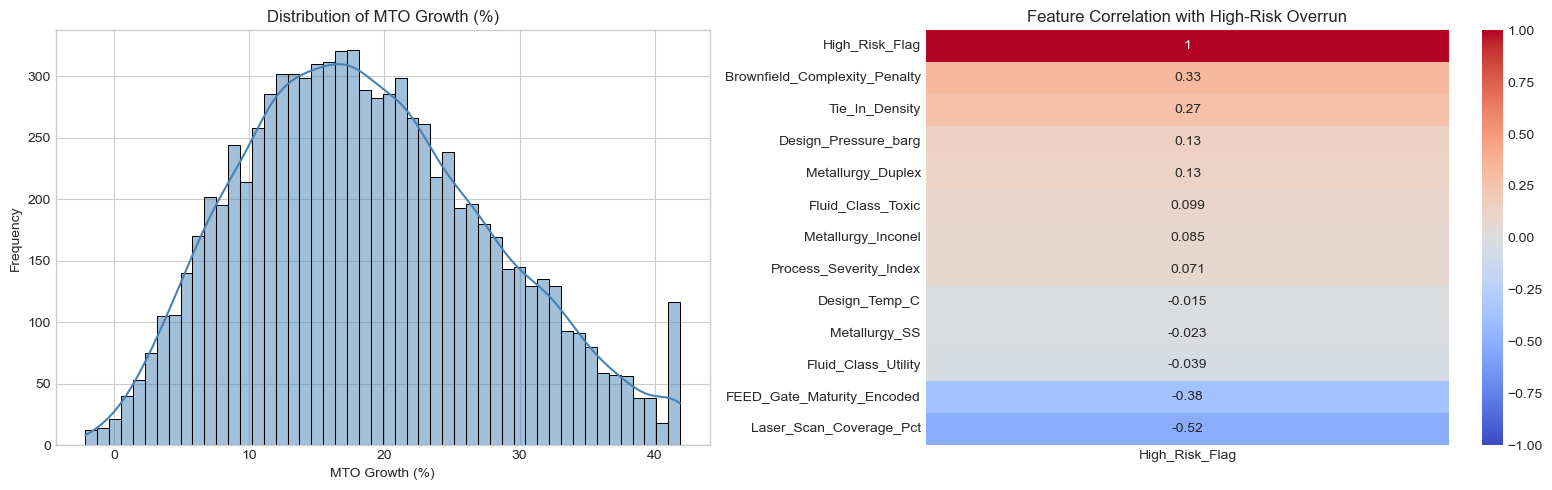

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Target Distribution
sns.histplot(df['MTO_Growth_Pct'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of MTO Growth (%)')
axes[0].set_xlabel('MTO Growth (%)')
axes[0].set_ylabel('Frequency')

# Correlation Heatmap
corr_df = X_scaled.copy()
corr_df['High_Risk_Flag'] = y_class
corr_matrix = corr_df.corr()

sns.heatmap(corr_matrix[['High_Risk_Flag']].sort_values(by='High_Risk_Flag', ascending=False), 
            annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Feature Correlation with High-Risk Overrun')

plt.tight_layout()
plt.show()

PCA reduced feature space from 12 to 10 principal components.


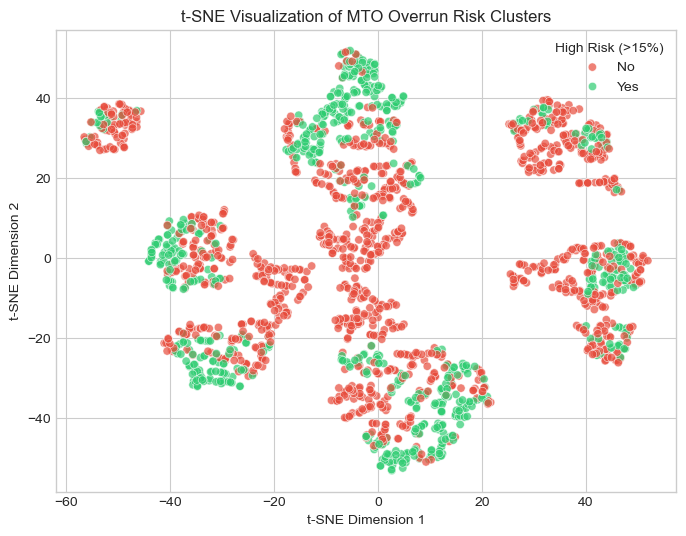

In [4]:
# Apply PCA to reduce dimensionality while retaining 95% variance
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"PCA reduced feature space from {X_scaled.shape[1]} to {X_pca.shape[1]} principal components.")

# Apply t-SNE for 2D visualization (Sampled for execution speed)
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
sample_idx = np.random.choice(X_scaled.shape[0], 2000, replace=False)
X_tsne = tsne.fit_transform(X_scaled.iloc[sample_idx])

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_class.iloc[sample_idx], 
                palette=['#2ecc71', '#e74c3c'], alpha=0.7)
plt.title('t-SNE Visualization of MTO Overrun Risk Clusters')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(title='High Risk (>15%)', labels=['No', 'Yes'])
plt.show()

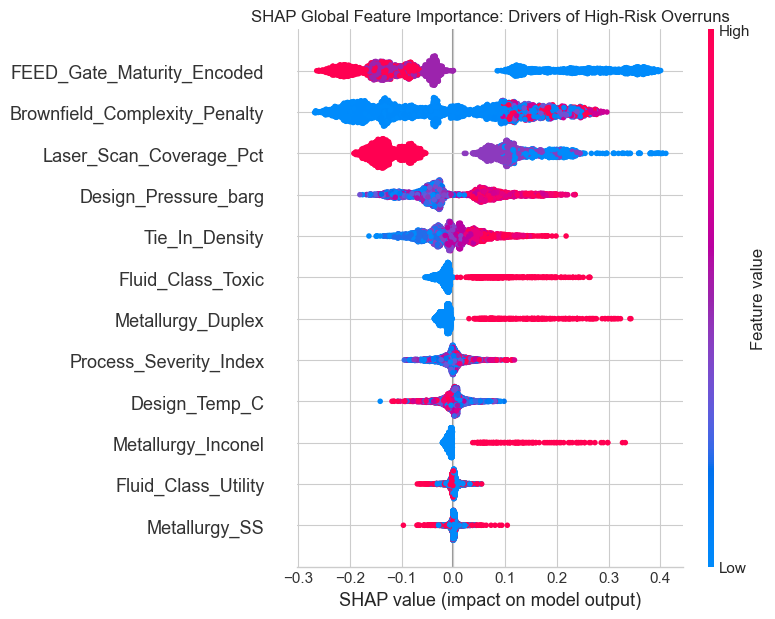


Top 5 Features by Mutual Information Score:
Brownfield_Complexity_Penalty    0.197159
Laser_Scan_Coverage_Pct          0.162819
FEED_Gate_Maturity_Encoded       0.095201
Tie_In_Density                   0.026645
Design_Pressure_barg             0.020468
dtype: float64


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Limit n_jobs to 2 to prevent CPU spike
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2)
rf_model.fit(X_scaled, y_class)

# Sample 3,000 records
X_sample = X_scaled.sample(3000, random_state=42)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_sample)

# Dynamically handle SHAP version differences to prevent shape mismatches
if isinstance(shap_values, list):
    shap_values_target = shap_values[1] # Older SHAP versions
elif len(np.array(shap_values).shape) == 3:
    shap_values_target = shap_values[:, :, 1] # Newer SHAP versions (3D matrix)
else:
    shap_values_target = shap_values

plt.figure(figsize=(10, 6))
plt.title("SHAP Global Feature Importance: Drivers of High-Risk Overruns")
shap.summary_plot(shap_values_target, X_sample, show=False) 
plt.tight_layout()
plt.show()

# Optional Filter Method (Mutual Information) confirmation
mi_scores = mutual_info_classif(X_scaled, y_class, random_state=42)
mi_series = pd.Series(mi_scores, index=X_scaled.columns).sort_values(ascending=False)
print("\nTop 5 Features by Mutual Information Score:")
print(mi_series.head())